In [15]:
# Import the libraries we need
import os
import re
import html
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [16]:
# Print the package versions used in this run (for reproducibility)
import sys, sklearn, numpy as np_check
print("python: ", sys.version.split()[0])
print("pandas: ", pd.__version__)
print("numpy: ", np_check.__version__)
print("scikit-learn: ", sklearn.__version__)

python:  3.12.4
pandas:  3.0.5
numpy:  2.5.3
scikit-learn:  1.9.1


In [17]:
# Folders and settings (paths are relative to the notebooks folder)
DATA_DIR= "../data"
MODEL_DIR= "../models"
os.makedirs(MODEL_DIR, exist_ok= True)

LABELS= {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}
LABEL_NAMES= ["World", "Sports", "Business", "Sci/Tech"]
SEED= 42

In [18]:
# Clean a headline: fix html symbols and remove the news source at the end, like (Reuters)
def clean_text(text):
    text= re.sub(r"\s?#39;", "'", str(text)).replace("quot;", '"')
    text= html.unescape(text)
    text= re.sub(r"<[^>]+>", " ", text) # remove html tags
    text= text.replace("\\", " ")
    text= re.sub(r"\s*\([^)]*\)\s*$", "", text) # remove (Reuters), (AFP), ...
    text= re.sub(r"\s+", " ", text)
    return text.strip()

print(clean_text("Wall St. Bears Claw Back Into the Black (Reuters)"))

Wall St. Bears Claw Back Into the Black


In [19]:
# Load the AG News data. We use the headline (title) only, not the description
# If the csv files are not in the data folder, download them first
URL= "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/"
os.makedirs(DATA_DIR, exist_ok= True)
for name in ["train", "test"]:
    path= f"{DATA_DIR}/{name}.csv"
    if not os.path.exists(path):
        print("downloading", name + ".csv ...")
        pd.read_csv(URL + name + ".csv", header= None).to_csv(path, index= False, header= False)

columns= ["label_id", "title", "description"]
train_df= pd.read_csv(f"{DATA_DIR}/train.csv", header= None, names= columns)
test_df= pd.read_csv(f"{DATA_DIR}/test.csv", header= None, names= columns)

for df in [train_df, test_df]:
    df["text"]= df["title"].apply(clean_text)
    df["label"]= df["label_id"].map(LABELS)

train_df= train_df[["text", "label"]]
test_df= test_df[["text", "label"]]

# Remove empty and duplicate headlines from the training data
train_df= train_df[train_df["text"].str.len() > 0].drop_duplicates()

print(f"train: {train_df.shape} - test: {test_df.shape}")
train_df.head()

train: (111447, 2) - test: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black,Business
1,Carlyle Looks Toward Commercial Aerospace,Business
2,Oil and Economy Cloud Stocks' Outlook,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,Business
4,"Oil prices soar to all-time record, posing new...",Business


In [20]:
# Split the training data: 90% train, 10% dev (dev is used to choose the best settings)
train, dev = train_test_split(train_df, test_size= 0.1, stratify= train_df["label"], random_state= SEED)
print(f"train: {len(train)} - dev: {len(dev)} - test: {len(test_df)}")
train["label"].value_counts()

train: 100302 - dev: 11145 - test: 7600


label
Sports      25995
World       25381
Business    24819
Sci/Tech    24107
Name: count, dtype: int64

In [21]:
# Training: try a few settings and keep the one with the best F1 on the dev set
best_f1= 0
best_model= None

for ngram in [(1, 1), (1, 2)]:
    for C in [1, 5, 10]:
        model= Pipeline([
            ("tfidf", TfidfVectorizer(ngram_range= ngram, min_df= 2, sublinear_tf= True, stop_words= "english")),
            ("clf", LogisticRegression(C= C, max_iter= 1000)),
        ])
        model.fit(train["text"], train["label"])

        pred= model.predict(dev["text"])
        accuracy= accuracy_score(dev["label"], pred)
        f1= f1_score(dev["label"], pred, average="macro")
        print(f"Ngram= {ngram} + C= {C}  ->  Model Accuracy= {accuracy:.4f} - F1-Score= {f1:.4f}")

        if f1 > best_f1:
            best_f1= f1
            best_model= model
            best_settings= (ngram, C)

print(f"\nBest settings: {best_settings} - dev F1: {round(best_f1, 4)}")

Ngram= (1, 1) + C= 1  ->  Model Accuracy= 0.8537 - F1-Score= 0.8525
Ngram= (1, 1) + C= 5  ->  Model Accuracy= 0.8488 - F1-Score= 0.8476
Ngram= (1, 1) + C= 10  ->  Model Accuracy= 0.8440 - F1-Score= 0.8428
Ngram= (1, 2) + C= 1  ->  Model Accuracy= 0.8587 - F1-Score= 0.8575
Ngram= (1, 2) + C= 5  ->  Model Accuracy= 0.8542 - F1-Score= 0.8531
Ngram= (1, 2) + C= 10  ->  Model Accuracy= 0.8494 - F1-Score= 0.8484

Best settings: ((1, 2), 1) - dev F1: 0.8575


In [22]:
# Save the best model in the models folder
joblib.dump(best_model, f"{MODEL_DIR}/tfidf_lr.joblib")
print("model saved")

model saved


In [23]:
# Testing: evaluate the best model on the test set (used only once, at the end)
y_test= test_df["label"]
y_pred= best_model.predict(test_df["text"])

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average= "macro"), 4))
print()
print(classification_report(y_test, y_pred, labels= LABEL_NAMES, digits= 4))

Accuracy: 0.8661
Macro F1: 0.8656

              precision    recall  f1-score   support

       World     0.8780    0.8600    0.8689      1900
      Sports     0.8859    0.9400    0.9122      1900
    Business     0.8373    0.8263    0.8318      1900
    Sci/Tech     0.8615    0.8379    0.8495      1900

    accuracy                         0.8661      7600
   macro avg     0.8657    0.8661    0.8656      7600
weighted avg     0.8657    0.8661    0.8656      7600



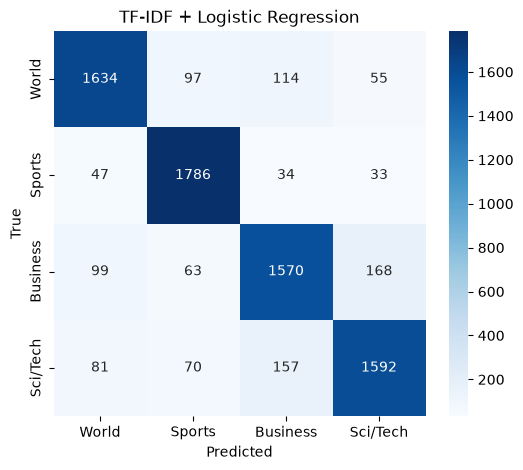

In [24]:
# Confusion matrix: rows are the true topic, columns are the predicted topic
cm= confusion_matrix(y_test, y_pred, labels= LABEL_NAMES)

plt.figure(figsize= (6, 5))
sns.heatmap(cm, annot= True, fmt= "d", cmap= "Blues", xticklabels= LABEL_NAMES, yticklabels= LABEL_NAMES)
plt.title("TF-IDF + Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [25]:
# Error analysis: Business and World are the topics the model mixes up the most
results= test_df.copy()
results["pred"]= y_pred

print("Business -> World:", ((results["label"] == "Business") & (results["pred"] == "World")).sum())
print("World -> Business:", ((results["label"] == "World") & (results["pred"] == "Business")).sum())

mistakes= results[(results["label"] != results["pred"]) & results["label"].isin(["Business", "World"])]
mistakes.head(10)

Business -> World: 99
World -> Business: 114


,text,label,pred
37,1994 Law Designed to Preserve Guard Jobs,World,Business
56,India's Tata expands regional footprint via Na...,World,Business
79,Live: Olympics day four,World,Sports
83,Intel to delay product aimed for high-definiti...,Business,Sci/Tech
88,U.S. Misses Cut in Olympic 100 Free,World,Sports
104,Mr Downer shoots his mouth off,World,Sports
106,Stocks Climb on Drop in Consumer Prices,World,Business
110,Yahoo! Ups Ante for Small Businesses,Business,Sci/Tech
120,Oil prices bubble to record high,World,Business
125,SUVs: Live And Let Die,Business,World


In [26]:
# Accuracy by headline length (number of words)
results["words"]= results["text"].str.split().str.len()
results["length"]= pd.cut(results["words"], bins= [0, 5, 8, 100], labels= ["<=5", "6-8", ">8"])
results["correct"]= results["label"] == results["pred"]
results.groupby("length", observed= True)["correct"].agg(["count", "mean"]).round(4)

,count,mean
length,,
<=5,2377,0.8368
6-8,4079,0.8745
>8,1144,0.8969


In [27]:
# Try It: load the saved model from the models folder (no retraining) and classify a new headline
tryit_model= joblib.load(f"{MODEL_DIR}/tfidf_lr.joblib")

def try_it(headline):
    if not headline or not headline.strip():
        print("Please type a news headline first (the input is empty).")
        return
    text= clean_text(headline)
    probs= tryit_model.predict_proba([text])[0]
    best= probs.argmax()
    print(f"Headline : {headline}")
    print(f"Predicted: {tryit_model.classes_[best]} ({probs[best] * 100:.1f}% confidence)")
    print()

try_it("Saudi Aramco reports higher quarterly profit as oil demand grows")
try_it("Al Hilal win the league after a late goal against Al Nassr")
try_it("") # blank input

Headline : Saudi Aramco reports higher quarterly profit as oil demand grows
Predicted: Business (96.9% confidence)

Headline : Al Hilal win the league after a late goal against Al Nassr
Predicted: Sports (97.6% confidence)

Please type a news headline first (the input is empty).
